# 04. Evaluation

This notebook comprises the "final exam".
We take the models we decided to keep at the end of notebook 3, train them on the whole training set, and score them on the test set.

We use the ROC AUC and PR AUC scores to rank the quality of the model, each with a confidence interval.
Nothing in this model influences a new choice, i.e., we simply report the numbers without tuning the model.

Start by loading the data.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

from src.dataset import load_clients, add_year_block, time_split
from src.features import TARGET, prepare
from src.models import build_pipeline

df = add_year_block(load_clients())
train, test = time_split(df)
X_train, y_train = prepare(train), train[TARGET]
X_test, y_test = prepare(test), test[TARGET]

## The four models

At the end of notebook 3 we decided to consider logistic regression and boosting, both with and without macros.
We kept the month as part of the datasets.
Set up the models in one go, then fit and score.

In [2]:
def make_boost():
    return HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=150,
        min_samples_leaf=200, early_stopping=False, random_state=0)

models = {
    "logreg + macro": build_pipeline(LogisticRegression(max_iter=1000), include_macro=True),
    "logreg, no macro": build_pipeline(LogisticRegression(max_iter=1000), include_macro=False),
    "boosting + macro": build_pipeline(make_boost(), include_macro=True),
    "boosting, no macro": build_pipeline(make_boost(), include_macro=False),
}

In [3]:
scores = {}
for label, model in models.items():
    model.fit(X_train, y_train)
    scores[label] = model.predict_proba(X_test)[:, 1]
    print(f"{label:20s} mean predicted {scores[label].mean():.3f}   "
          f"ROC AUC {roc_auc_score(y_test, scores[label]):.3f}")

logreg + macro       mean predicted 0.254   ROC AUC 0.748
logreg, no macro     mean predicted 0.175   ROC AUC 0.700
boosting + macro     mean predicted 0.082   ROC AUC 0.612
boosting, no macro   mean predicted 0.087   ROC AUC 0.659


We observe that:
- Boosting is clearly behind logistic regression on the test set. This matches our findings in notebook 3.
- Boosting hardly moved its predictions with respect to the training set. We recall that the training set had a subscription rate of only 6.4%, whereas the test rate is 31%. Boosting stayed around 8%, while logistic regression hit 17% and 25%. The actual rates in the two blocks are 23.7% and 52.1%.
- Macro features help logistic regression (ROC AUC 0.748 with vs 0.700 without) but make boosting worse on the full test (0.612 vs 0.659). Boosting does benefit from them in the block 1 tail (0.658 vs 0.609), so the effect for boosting is not consistent.

One potential explanation for logistic regression being better is that decision trees can't extrapolate.
A tree sorts clients into groups based on feature thresholds seen during training.
Thus, a test client with an interest rate lower than anything seen in training ends up in the group corresponding to the lowest rates seen, and gets a score similar to those.
By contrast, a logistic regression instead assumes that a lower interest rate means a higher subscription rate, and draws a straight line past whatever appeared in training.
This line happened to continue in the right direction here.
If this is so, then part of logistic regression's advantage comes from the trend continuing as guessed and not from a better understanding of clients.
Let us test this with the following code:

In [4]:
print(train["euribor3m"].min(), test["euribor3m"].min())
print(pd.Series(scores["boosting + macro"]).groupby(test["year_block"].to_numpy()).mean())

1.299 0.634
1    0.075580
2    0.101397
dtype: float64


The first line prints the lowest interest rate in the training and test sets.
The test minimum is clearly lower, so the test set contains interest rates well below what the models saw during training.
The second line prints boosting's average prediction in each test block.
They stay modest at 7% and 10%, compared to the actual rates of 23.7% and 52.1%, supporting the hypothesis that the trees' predictions stay close to what they saw during training.

## Metrics with bootstrap intervals

Let us now understand the model scores better by bootstrapping the resulting metrics.
The bootstrap is a way to estimate how much a metric would vary if we had used a different test set of the same size (in this case 8236 rows).
For this we do the following:
1. Draw 8236 rows from the test set with replacement. Thus, some rows may appear more than once and some not at all.
2. Compute the metric on that resampled set.
3. Repeat the above steps 1000 times.
4. Take the 2.5th and 97.5th percentiles of the 1000 results, giving a 95% confidence interval.

A wide interval means the number is shaky, and a narrow one means that it's stable.

In [14]:
from sklearn.metrics import average_precision_score

rng = np.random.default_rng(0)

def bootstrap_ci(y, s, metric, n_boot=1000):
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        stats.append(metric(y[idx], s[idx]))
    return np.percentile(stats, [2.5, 97.5])

In [15]:
def summarize(y, p):
    out = {"base rate": round(y.mean(), 3)}
    for name, metric in [("ROC AUC", roc_auc_score), ("PR AUC", average_precision_score)]:
        lo, hi = bootstrap_ci(y, p, metric)
        out[name] = f"{metric(y, p):.3f} [{lo:.3f}, {hi:.3f}]"
    return out

views = {"full test": np.ones(len(test), dtype=bool),
         "block 1 tail": (test["year_block"] == 1).to_numpy(),
         "block 2": (test["year_block"] == 2).to_numpy()}

rows = []
for label, s in scores.items():
    for view, mask in views.items():
        rows.append({"model": label, "view": view,
                     **summarize(y_test.to_numpy()[mask], s[mask])})
pd.DataFrame(rows)

,model,view,base rate,ROC AUC,PR AUC
0,logreg + macro,full test,0.308,"0.748 [0.736, 0.759]","0.527 [0.509, 0.549]"
1,logreg + macro,block 1 tail,0.237,"0.733 [0.718, 0.747]","0.439 [0.416, 0.466]"
2,logreg + macro,block 2,0.521,"0.654 [0.633, 0.678]","0.632 [0.604, 0.666]"
3,"logreg, no macro",full test,0.308,"0.700 [0.688, 0.713]","0.496 [0.474, 0.517]"
4,"logreg, no macro",block 1 tail,0.237,"0.672 [0.657, 0.688]","0.400 [0.374, 0.426]"
5,"logreg, no macro",block 2,0.521,"0.645 [0.621, 0.669]","0.625 [0.593, 0.662]"
6,boosting + macro,full test,0.308,"0.612 [0.598, 0.626]","0.406 [0.387, 0.425]"
7,boosting + macro,block 1 tail,0.237,"0.658 [0.642, 0.672]","0.361 [0.338, 0.384]"
8,boosting + macro,block 2,0.521,"0.570 [0.543, 0.598]","0.563 [0.533, 0.594]"
9,"boosting, no macro",full test,0.308,"0.659 [0.646, 0.672]","0.468 [0.447, 0.488]"


In all cases the bootstrap gives roughly ±0.015 on the block 1 tail and ±0.025 on block 2.
Non-overlapping intervals indicate a true gap, but overlapping ones don't prove that two models are equal.
Some observations:
- In the block 1 tail, logistic regression with macro data is clearly the best (its interval, [0.718, 0.747], is above all the others). Boosting without macro is clearly the lowest. The two middle models (logistic regression without macro and boosting with macro) have overlapping intervals, so we cannot separate them.
- In block 2, three models are indistinguishable as they sit around 0.64 to 0.65 with heavily overlapping intervals. Boosting with macro is clearly lower at 0.570, and its upper end is below the others' lower ends.
- The drop from the block 1 tail to block 2 is likely real. Logistic regression with macro goes from 0.733 [0.718, 0.747] to 0.654 [0.633, 0.678], where the intervals don't overlap.
- The macro columns help logistic regression in the block 1 tail (0.733 vs 0.672) but make no difference in block 2 (0.654 vs 0.645). This matches the trend hypothesis by which a trend continues in the near term but not very far into the future, giving negligible change in year 2.
- The full-test numbers seem less trustworthy than the parts. For boosting without macro, the combined score of 0.659 is above both of its parts (0.609 and 0.643).
- PR AUC against base rates: the best model reaches 0.439 against 0.237 in the block 1 tail (about 1.9x), and 0.632 against 0.521 in block 2 (about 1.2x).

## Calibration

From here on we restrict ourselves to the two logistic regression models, as they're the main candidates.

We now calibrate the model. We sort clients by predicted probability, divide them into ten equal groups, and in each group we compare the average predicted probability with the actual subscription rate.
We plot the results, with mean predicted probability on the $x$ axis and actual probability on the $y$ axis.
Points on the diagonal indicate that the scores can really be read as probabilities.
Meanwhile, points above the diagonal mean the model underpredicts (actual probability is higher than predicted probability) and below the diagonal it overpredicts (vice-versa).

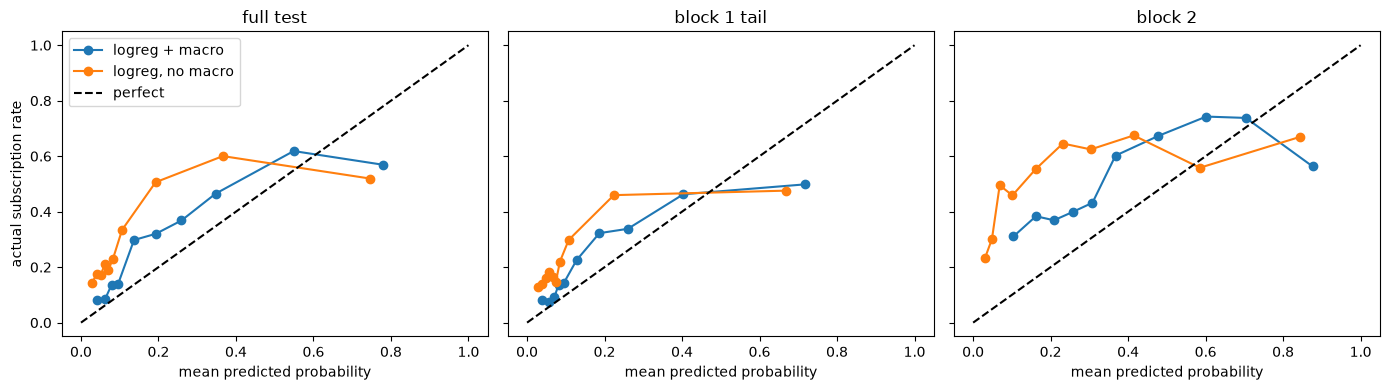

In [7]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

y_arr = y_test.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, (view, mask) in zip(axes, views.items()):
    for label in ["logreg + macro", "logreg, no macro"]:
        frac_pos, mean_pred = calibration_curve(
            y_arr[mask], scores[label][mask], n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o", label=label)
    ax.plot([0, 1], [0, 1], "k--", label="perfect")
    ax.set_title(view)
    ax.set_xlabel("mean predicted probability")
axes[0].set_ylabel("actual subscription rate")
axes[0].legend()
plt.tight_layout()

In the low and middle range (predicted 0.05 to 0.4) points sit above the diagonal in all cases, so the models underpredict.
In block 2 the gap is particularly large, with a predicted 0.10 corresponding to an actual rate of about 0.31 for the macro model, and a predicted 0.03 to 0.05 corresponding to roughly 0.23 to 0.30 for the no-macro model.
In the top bins the lines flatten or bend back down.
In the full test, the bin with the highest score for the macro model has a predicted 0.78 and an actual 0.57, and thus lies below the diagonal.

Note that the ordering at the top (by which the highest bin often has a lower actual rate than the bin before it) isn't reliable.
In the full test (with 824 clients per bin) the standard error is about 0.017, so a 0.05 drop likely is real.
However, in the block 2 test (with 206 clients per bin), the standard error is about 0.035, so a lot of the zigzag is probably noise.

All in all, this means that while the scores do order clients usefully, they can't be read as probabilities.
They are too low for most clients and too high for some at the very top.
If these were to be used for expected revenue we would have to first recalibrate using recent data.

## Gains table

We now sort the clients by score (highest first), divide them into ten equal groups, and count the subscribers in each.
Then we can see what share of subscribers we reach if we call the top 20% of clients.

`np.arange(len(d)) * n_groups // len(d) + 1` numbers the sorted rows 1 to 10 in group of equal size, with decile 1 holding the top 10% of the list.
"Cum lift" is how many times better than random calling the top part of the list is, e.g., a lift of 2.0 at 20% means the top 20% of the list contains twice as many subscribers as a random fifth would.

In [8]:
def gains_table(y, s, n_groups=10):
    d = pd.DataFrame({"y": y, "s": s}).sort_values("s", ascending=False).reset_index(drop=True)
    d["decile"] = np.arange(len(d)) * n_groups // len(d) + 1
    g = d.groupby("decile")["y"].agg(clients="count", subscribers="sum")
    g["rate"] = g["subscribers"] / g["clients"]
    g["cum % of clients"] = g["clients"].cumsum() / len(d)
    g["cum % of subscribers"] = g["subscribers"].cumsum() / d["y"].sum()
    g["cum lift"] = g["cum % of subscribers"] / g["cum % of clients"]
    return g.round(3)

for view, mask in views.items():
    print(view)
    display(gains_table(y_arr[mask], scores["logreg + macro"][mask]))

full test


,clients,subscribers,rate,cum % of clients,cum % of subscribers,cum lift
decile,,,,,,
1,824,469,0.569,0.1,0.185,1.846
2,824,509,0.618,0.2,0.385,1.925
3,823,383,0.465,0.3,0.536,1.787
4,824,303,0.368,0.4,0.655,1.638
5,823,264,0.321,0.5,0.759,1.519
6,824,245,0.297,0.6,0.856,1.426
7,824,115,0.140,0.7,0.901,1.287
8,823,113,0.137,0.8,0.946,1.182
9,824,70,0.085,0.9,0.973,1.081


block 1 tail


,clients,subscribers,rate,cum % of clients,cum % of subscribers,cum lift
decile,,,,,,
1,618,308,0.498,0.1,0.210,2.100
2,618,286,0.463,0.2,0.405,2.025
3,618,209,0.338,0.3,0.548,1.825
4,618,200,0.324,0.4,0.684,1.710
5,617,138,0.224,0.5,0.778,1.557
6,618,88,0.142,0.6,0.838,1.397
7,618,84,0.136,0.7,0.896,1.279
8,618,56,0.091,0.8,0.934,1.167
9,618,47,0.076,0.9,0.966,1.073


block 2


,clients,subscribers,rate,cum % of clients,cum % of subscribers,cum lift
decile,,,,,,
1,206,116,0.563,0.1,0.108,1.080
2,206,152,0.738,0.2,0.250,1.248
3,206,153,0.743,0.3,0.392,1.307
4,206,138,0.670,0.4,0.521,1.301
5,205,124,0.605,0.5,0.637,1.273
6,206,89,0.432,0.6,0.719,1.199
7,206,83,0.403,0.7,0.797,1.138
8,206,75,0.364,0.8,0.867,1.083
9,206,79,0.383,0.9,0.940,1.044


We clearly observe the following:
- Block 1 tail: calling the top 20% reaches 40.5% of subscribers, with a lift of 2, thus twice as much as random calling would. This is a solid result for such a simple model.
- Block 2: reaches 25%, only a little above the 20% of random calling. Furthermore, deciles 2-4 have a higher subscription rate than the top decile, so the very top of the list is misordered.

We also note that lifts have an upper bound when the base rate is high. With a 52% subscription rate calling 10% of clients can at best reach about 19% of the subscribers, so lifts in block 2 are naturally lower than in the tail of block 1. Even so, however, 1.08 at the top decile is still weak.

## Within-period check

Previously we tested the month of May and the results suggested that much of the AUC came from telling periods apart.
Let's test this idea more thoroughly.
We score each month inside each block separately, so that the macro and calendar clock carry little information.
That is also closest to the real decision because an advisor would rank clients within one campaign period.

In [11]:
rows = []
for (blk, mon), idx in test.groupby(["year_block", "month"]).indices.items():
    y = y_arr[idx]
    if y.sum() < 50 or (1 - y).sum() < 50:   # skip groups too small for a stable AUC
        continue
    rows.append({"block": blk, "month": mon, "clients": len(idx),
                 "base rate": round(y.mean(), 3),
                 **{label: round(roc_auc_score(y, scores[label][idx]), 3)
                    for label in ["logreg + macro", "logreg, no macro"]}})
pd.DataFrame(rows)

,block,month,clients,base rate,logreg + macro,"logreg, no macro"
0,1,aug,770,0.343,0.597,0.602
1,1,dec,172,0.512,0.617,0.616
2,1,jul,177,0.367,0.563,0.548
3,1,jun,715,0.369,0.603,0.607
4,1,may,3274,0.101,0.584,0.592
5,1,nov,357,0.471,0.680,0.684
6,1,oct,446,0.404,0.608,0.616
7,1,sep,267,0.397,0.656,0.660
8,2,apr,174,0.557,0.631,0.602
9,2,aug,233,0.515,0.796,0.811


Within a single month, the model still ranks clients with real skill. The logistic regression with macro features has a ROC AUC between 0.56 and 0.68 in each month of block 1, and between 0.63 and 0.80 in each month of block 2 (months with fewer than 50 subscribers or 50 non-subscribers are skipped). Removing the macro columns changes the monthly ROC AUC by at most 0.03, and the change goes in both directions.

This confirms two things. First, inside a period the skill comes from client and contact features and not from the macro "clock". Second, the pooled test numbers mix two tasks, ranking clients and telling periods apart. For this reason the within-month numbers are the more honest ones for the real decision (an advisor ranks clients inside one campaign period). In block 2 the monthly ROC AUC (average about 0.72) is higher than the pooled block 2 value (0.654), meaning that the model ranks clients better within a month than across months.

Let us also study the clients who had been contacted previously and check whether the outcome of this campaign is somehow related to that of the previous one.

In [12]:
X_all = prepare(df)
print(X_all["contacted_before"].groupby(df["year_block"]).mean().round(3))
print(df.groupby(["year_block", "poutcome"])["subscribed"].agg(["count", "mean"]).round(3))

year_block
0    0.001
1    0.066
2    0.352
Name: contacted_before, dtype: float64
                        count   mean
year_block poutcome                 
0          failure        699  0.034
           nonexistent  26948  0.049
           success         35  0.086
1          failure       2986  0.129
           nonexistent   7760  0.187
           success        690  0.568
2          failure        567  0.346
           nonexistent    843  0.448
           success        648  0.770


The client mix changed a lot over time. The share of previously contacted clients grows from 0.1% (block 0) to 6.6% (block 1) and 35.2% (block 2), and the outcome of the previous campaign (poutcome) is strongly linked to subscription: among clients with a previous success, 56.8% subscribed in block 1 and 77.0% in block 2.

However, the subscription rate also rose within every poutcome group (for example, "nonexistent" goes from 4.9% to 18.7% to 44.8%), so the shift is not only a change in who was called: clients subscribed more across the board in later periods. This helps explain why the model underpredicts in the calibration section, since it learned from a period when these rates were much lower. (Block 0 has only 35 "success" clients, so its 8.6% is noisy.)

Finally, let us see what happens if we only rank the clients by the outcome of their previous campaign.

In [13]:
order = {"failure": 0, "nonexistent": 1, "success": 2}
pout_score = test["poutcome"].map(order).to_numpy()

rows = []
for (blk, mon), idx in test.groupby(["year_block", "month"]).indices.items():
    y = y_arr[idx]
    if y.sum() < 50 or (1 - y).sum() < 50:
        continue
    rows.append({"block": blk, "month": mon,
                 "poutcome only": roc_auc_score(y, pout_score[idx]),
                 "logreg + macro": roc_auc_score(y, scores["logreg + macro"][idx])})

pd.DataFrame(rows).groupby("block")[["poutcome only", "logreg + macro"]].mean().round(3)

,poutcome only,logreg + macro
block,,
1,0.594,0.613
2,0.684,0.720


Ranking clients by the outcome of their previous campaign alone gives an average monthly ROC AUC of 0.594 in block 1 and 0.684 in block 2, against 0.613 and 0.720 for the logistic regression with the entirety of the data. So most of the model's within-period skill comes from a single feature, and all the other features together add only about 0.02 to 0.04. Note that these are unweighted averages over months, and that months with few subscribers or non-subscribers were skipped.

## Conclusions

- **The model has ranking skill, but it depends on the period.** ROC AUC is 0.733 [0.718, 0.747] in the period right after training and 0.654 [0.633, 0.678] in the newest one, and the intervals do not overlap.
- **Logistic regression is the best model.** Gradient boosting doesn't beat it, probably because trees cannot extrapolate to interest rates below anything seen in training.
- **The scores are not probabilities.** The model underpredicts for most clients, so it would need recalibrating on recent data before being used for anything like expected revenue.
- **What this means for calling clients.** In the block 1 tail, calling the top 20% of the list reaches 40.5% of subscribers (lift 2.0). In block 2 it reaches only 25.0%, and the top of the list is misordered (deciles 2 to 4 have a higher subscription rate than decile 1).
- **Inside one period, skill remains.** Month by month the ROC AUC is 0.56 to 0.80, but most of it comes from the outcome of the previous campaign alone.
- **Limits.** One bank, one campaign period, a deliberately hard test (subscription rate 6.4% in training vs 30.8% in testing), and no deployment, monitoring, or retraining. The numbers are a stress test of the approach and not a forecast.